# Quiz 1：機器學習二元分類

**對應講義：第 72 頁；涵蓋基礎與進階。**

1. 建立有 8 個輸入特徵的模擬二元分類資料，切分訓練／驗證集。
2. 以 `StandardScaler` 縮放特徵，訓練 Logistic Regression 與 Random Forest。
3. 比較門檻 0.50、0.35 與訓練集交叉驗證選出的門檻。
4. 顯示混淆矩陣與四個分類指標，解釋 FP／FN 與 Precision／Recall。

這份資料由 `make_classification` 產生，**不是信用卡真實資料**。
AI 協作紀錄：ChatGPT／Codex 協助把題目整理成步驟、撰寫程式與說明，並執行驗證；下列數字由實際執行產生。

## 1. 子目標：匯入套件與設定路徑
固定亂數種子，方便重跑。預期看到 HW2 路徑與 seed。

In [1]:
# 子目標：找到 HW2 根目錄，讓本機 Jupyter、VS Code 與 Colab 使用同一份路徑設定。
from pathlib import Path
import os
import random
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

if os.environ.get("HW2_ROOT"):
    ROOT = Path(os.environ["HW2_ROOT"]).expanduser().resolve()
else:
    candidates = [Path.cwd(), Path.cwd() / "HW2", Path.cwd() / "output" / "HW2"]
    ROOT = next((p for p in candidates if (p / "data" / "UCI_Credit_Card.csv").is_file()), None)
    if ROOT is None:
        raise FileNotFoundError("找不到 HW2。請從解壓後的 HW2 開啟 Notebook；Colab 設 HW2_ROOT=/content/HW2。")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("HW2:", ROOT)
print("random seed:", SEED)

HW2: /workspace/scratch/70c916837713/output/HW2
random seed: 42


## 2. 子目標：建立至少 5 個 X 欄位的二元分類資料
`X` 是 `(3000, 8)`，`y` 是 `(3000,)`。故意讓欄位尺度不同，以展示縮放的作用。
正類 1 約占 30%，負類 0 約占 70%。

In [2]:
# 子目標：產生模擬資料，並檢查資料形狀、類別分布與特徵尺度。
from sklearn.datasets import make_classification
X, y = make_classification(
    n_samples=3000, n_features=8, n_informative=5, n_redundant=2,
    n_classes=2, weights=[0.70, 0.30], class_sep=1.15,
    flip_y=0.03, random_state=SEED,
)
X = X * np.array([1, 1000, 0.01, 10, 100, 0.1, 10000, 1])
feature_names = [f"feature_{i+1}" for i in range(X.shape[1])]
df = pd.DataFrame(X, columns=feature_names)
df["target"] = y
OUT = ROOT / "results" / "quiz1"
OUT.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT / "synthetic_binary_data.csv", index=False)
display(df.head())
display(df["target"].value_counts().rename_axis("Label").to_frame("Count"))
display(df[feature_names].agg(["mean", "std", "min", "max"]).T)
print("X shape:", X.shape, "y shape:", y.shape)

X shape: (3000, 8) y shape: (3000,)


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,target
0,-2.515226,657.635665,-0.042214,33.838685,254.550127,0.066802,48348.708849,2.680817,0
1,-3.045044,259.708176,-0.015919,-21.330450,243.250145,-0.112678,10674.214170,3.626189,0
2,-0.262547,5.143141,-0.021118,16.435353,91.614939,0.100902,26397.135857,1.857519,0
3,1.946962,268.744719,0.016103,-8.354755,-71.064673,-0.026223,-10187.410218,-1.398261,1
4,-2.565690,17.812923,-0.012943,-20.932251,41.106521,-0.075853,-4561.826900,2.918561,0


,Count
Label,
0,2095
1,905


,mean,std,min,max
feature_1,-0.811837,1.694715,-6.186879,6.775224
feature_2,29.091757,1002.161903,-3540.961146,3777.489976
feature_3,-0.003448,0.020353,-0.087269,0.067815
feature_4,3.160658,16.331953,-43.857006,63.145279
feature_5,-2.228695,172.104079,-587.332657,731.370529
feature_6,0.082724,0.160370,-0.445690,0.593025
feature_7,-1132.946437,29530.812641,-74207.684604,115139.446466
feature_8,0.796462,1.539829,-6.476539,6.502936


## 3. 子目標：切分資料與避免縮放資料洩漏
80% 為訓練集、20% 為驗證集；`stratify=y` 保留兩類比例。
Pipeline 在每次 `fit` 只以當次訓練資料估計平均值與標準差，驗證資料只接受 `transform`。
兩個模型都使用同一個切分。Random Forest 不依賴縮放，但同樣放入 Pipeline，讓流程一致。

In [3]:
# 子目標：建立同一組訓練／驗證資料及兩種分類模型。
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

train_idx, val_idx = train_test_split(
    np.arange(len(y)), test_size=0.20, stratify=y, random_state=SEED,
)
X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=SEED)),
    ]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(n_estimators=200, max_depth=8,
            min_samples_leaf=4, random_state=SEED, n_jobs=2)),
    ]),
}
print("Train:", X_train.shape, "Validation:", X_val.shape)
assert not set(train_idx) & set(val_idx)
demo_scaler = StandardScaler().fit(X_train)
display(pd.DataFrame({
    "Feature": feature_names,
    "Raw training std": X_train.std(axis=0),
    "Scaled training std": demo_scaler.transform(X_train).std(axis=0),
}))

Train: (2400, 8) Validation: (600, 8)


,Feature,Raw training std,Scaled training std
0,feature_1,1.705113,1.0
1,feature_2,1004.013910,1.0
2,feature_3,0.020532,1.0
3,feature_4,16.424941,1.0
4,feature_5,171.544475,1.0
5,feature_6,0.160665,1.0
6,feature_7,29696.495016,1.0
7,feature_8,1.543681,1.0


## 4. 子目標：定義四個指標
混淆矩陣的**列為真實標籤、欄為預測標籤**，順序均為 `[0, 1]`。

| 名稱 | 意義 |
|---|---|
| TN | 負類正確預測為 0 |
| FP | 負類被誤判為 1：誤報 |
| FN | 正類被誤判為 0：漏報 |
| TP | 正類正確預測為 1 |
| Accuracy | `(TP + TN) / 全部樣本` |
| Precision | `TP / (TP + FP)`：預測為正類中，有多少是真的正類 |
| Recall | `TP / (TP + FN)`：真正正類中，找到了多少 |
| F1 | Precision 與 Recall 的調和平均 |

In [4]:
# 子目標：統一計算 Accuracy、Precision、Recall、F1，以及四種混淆矩陣計數。
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

def classification_metrics(y_true, probability, threshold=0.5):
    prediction = (np.asarray(probability) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    return {
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, prediction),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

print("Positive label = 1; prediction = 1 when probability >= threshold")

Positive label = 1; prediction = 1 when probability >= threshold


## 5. 主目標：訓練兩種模型，取得機率並選擇門檻
先用 0.50 分類，再把門檻降為 0.35，觀察微調的效果。
另以**訓練集內的三折交叉驗證**取得每筆訓練樣本的 out-of-fold 機率，
搜尋 F1 最大的門檻；每筆樣本的分數都來自未看過該筆資料的模型。
選好門檻後才評估驗證集，避免用驗證標籤挑門檻。

In [5]:
# 主目標：訓練、調整門檻，並在同一驗證集計算各項指標。
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
threshold_grid = np.round(np.arange(0.10, 0.91, 0.01), 2)
rows, probabilities, selected_thresholds, cv_rows = [], {}, {}, []
for name, model in models.items():
    oof_prob = cross_val_predict(model, X_train, y_train,
        cv=cv, method="predict_proba", n_jobs=1)[:, 1]
    cv_f1 = np.array([f1_score(y_train, oof_prob >= t, zero_division=0)
                      for t in threshold_grid])
    # 平手時採用搜尋順序中的第一個門檻，規則固定且可重現。
    selected = float(threshold_grid[np.argmax(cv_f1)])
    selected_thresholds[name] = selected
    cv_rows.extend({"Model": name, "Threshold": float(t), "OOF_F1": float(s)}
                   for t, s in zip(threshold_grid, cv_f1))
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_val)[:, 1]
    probabilities[name] = prob
    for setting, threshold in [("Initial", 0.50), ("Adjusted", 0.35),
                                ("Train-CV selected", selected)]:
        rows.append({"Model": name, "Setting": setting,
                     **classification_metrics(y_val, prob, threshold)})
    print(f"{name}: selected threshold = {selected:.2f}; OOF F1 = {cv_f1.max():.4f}")
metrics_df = pd.DataFrame(rows)
metrics_df.to_csv(OUT / "classification_metrics.csv", index=False)
pd.DataFrame(cv_rows).to_csv(OUT / "threshold_search.csv", index=False)
display(metrics_df.round(4))

Logistic Regression: selected threshold = 0.45; OOF F1 = 0.6526
Random Forest: selected threshold = 0.30; OOF F1 = 0.8050


,Model,Setting,Threshold,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,Logistic Regression,Initial,0.50,0.8367,0.8547,0.5525,0.6711,402,17,81,100
1,Logistic Regression,Adjusted,0.35,0.8200,0.6891,0.7348,0.7112,359,60,48,133
2,Logistic Regression,Train-CV selected,0.45,0.8417,0.8209,0.6077,0.6984,395,24,71,110
3,Random Forest,Initial,0.50,0.8883,0.8958,0.7127,0.7938,404,15,52,129
4,Random Forest,Adjusted,0.35,0.9083,0.8387,0.8619,0.8501,389,30,25,156
5,Random Forest,Train-CV selected,0.30,0.8900,0.7751,0.8950,0.8308,372,47,19,162


## 6. 主目標：呈現門檻調整前後的混淆矩陣
每一列固定一種模型，三欄依序為原始、微調與訓練集選定的門檻。
在同一模型與同一批資料上降低門檻，TP／FP 不會減少、FN 不會增加，Recall 不會降低；
Precision 的變化則要看實際資料，並不保證一定下降。

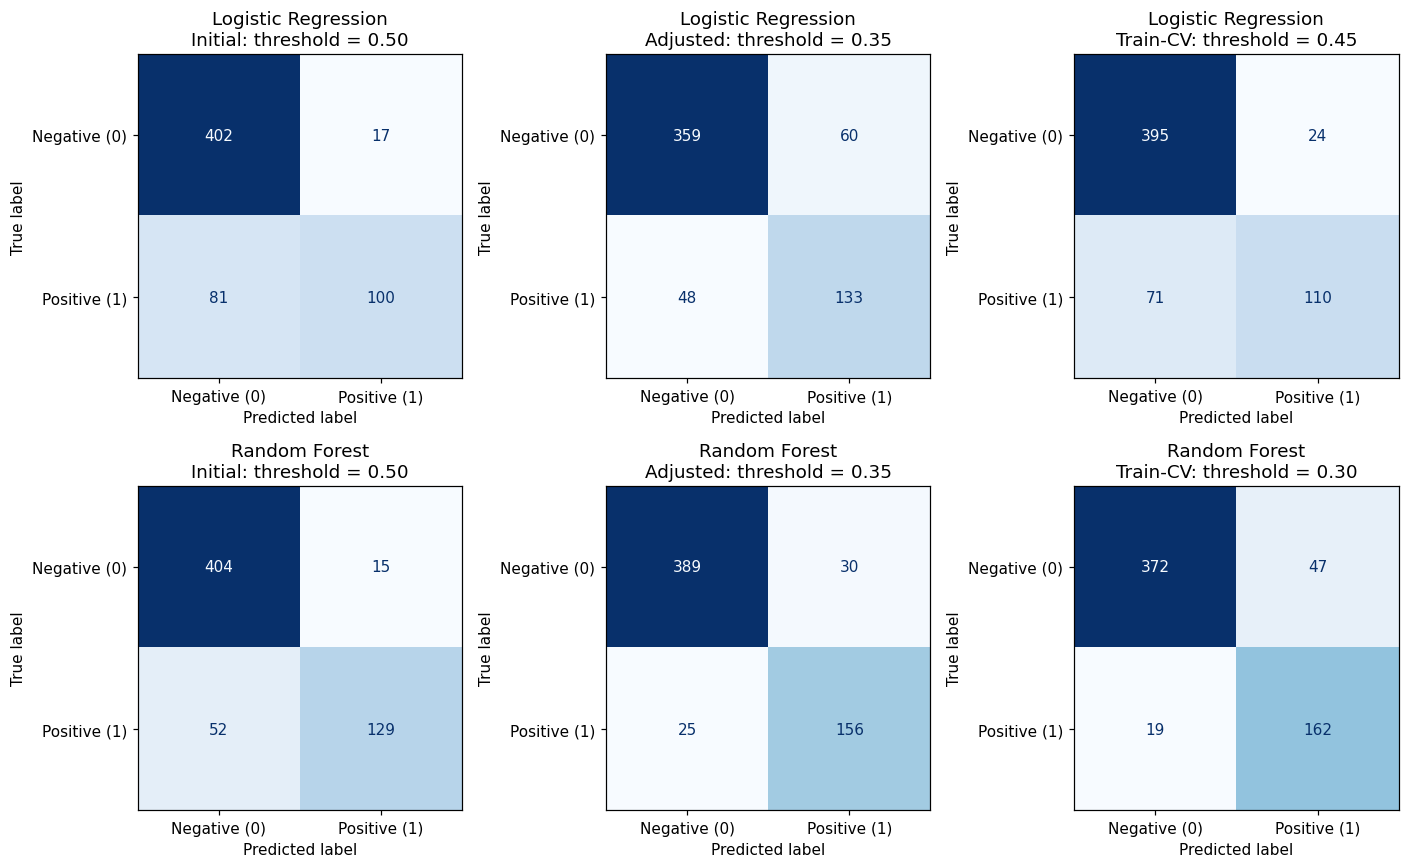

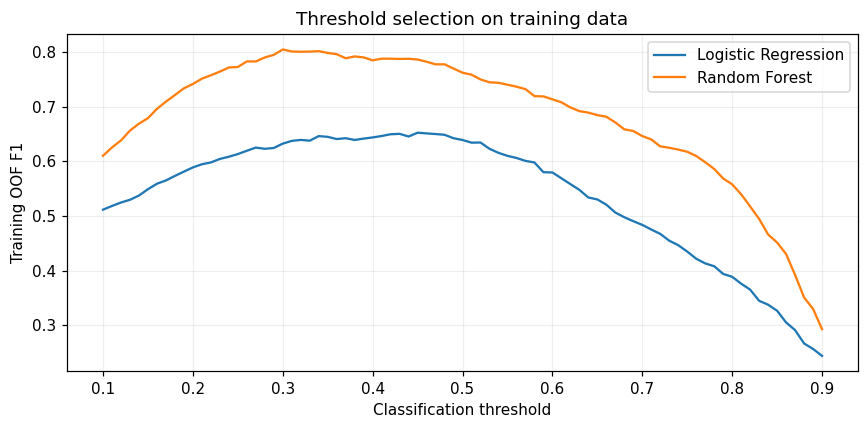

In [6]:
# 主目標：畫出兩模型、三種門檻的混淆矩陣。
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for row, (name, prob) in enumerate(probabilities.items()):
    settings = [("Initial", 0.50), ("Adjusted", 0.35),
                ("Train-CV", selected_thresholds[name])]
    for col, (setting, threshold) in enumerate(settings):
        ConfusionMatrixDisplay.from_predictions(y_val, prob >= threshold,
            labels=[0, 1], display_labels=["Negative (0)", "Positive (1)"],
            cmap="Blues", colorbar=False, ax=axes[row, col])
        axes[row, col].set_title(f"{name}\n{setting}: threshold = {threshold:.2f}")
fig.tight_layout()
fig.savefig(OUT / "confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4))
for name in models:
    subset = pd.DataFrame(cv_rows).query("Model == @name")
    ax.plot(subset["Threshold"], subset["OOF_F1"], label=name)
ax.set(xlabel="Classification threshold", ylabel="Training OOF F1", title="Threshold selection on training data")
ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "threshold_search.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## 7. 主目標：比較 Precision、Recall 與錯誤類型
以下說明依剛才產生的數字自動更新，不預先假設哪一個模型一定比較好。

In [7]:
# 主目標：用實測指標撰寫比較說明。
selected_rows = metrics_df[metrics_df["Setting"] == "Train-CV selected"].copy()
display(selected_rows.round(4))
lines = ["### 實測觀察"]
for _, r in selected_rows.iterrows():
    larger = "漏報 FN" if r["FN"] > r["FP"] else "誤報 FP" if r["FP"] > r["FN"] else "兩類錯誤相同"
    lines.append(f"- **{r['Model']}**：門檻 {r['Threshold']:.2f}，"
        f"Precision={r['Precision']:.4f}、Recall={r['Recall']:.4f}、F1={r['F1']:.4f}；"
        f"FP={int(r['FP'])}、FN={int(r['FN'])}，{larger}較多。" if r['FP'] != r['FN'] else
        f"- **{r['Model']}**：FP 與 FN 相同，均為 {int(r['FP'])}。")
for metric in ["Precision", "Recall", "F1"]:
    best = selected_rows.loc[selected_rows[metric].idxmax()]
    lines.append(f"- 本次 {metric} 較高的是 **{best['Model']}**（{best[metric]:.4f}）。")
lines.append("- 模擬資料的非線性結構可能影響兩模型差異；結果僅代表這次固定切分，不能推論所有資料都相同。")
report = "\n".join(lines)
display(Markdown(report))
_ = (OUT / "observations.md").write_text(report + "\n", encoding="utf-8")

,Model,Setting,Threshold,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
2,Logistic Regression,Train-CV selected,0.45,0.8417,0.8209,0.6077,0.6984,395,24,71,110
5,Random Forest,Train-CV selected,0.30,0.8900,0.7751,0.8950,0.8308,372,47,19,162


### 實測觀察
- **Logistic Regression**：門檻 0.45，Precision=0.8209、Recall=0.6077、F1=0.6984；FP=24、FN=71，漏報 FN較多。
- **Random Forest**：門檻 0.30，Precision=0.7751、Recall=0.8950、F1=0.8308；FP=47、FN=19，誤報 FP較多。
- 本次 Precision 較高的是 **Logistic Regression**（0.8209）。
- 本次 Recall 較高的是 **Random Forest**（0.8950）。
- 本次 F1 較高的是 **Random Forest**（0.8308）。
- 模擬資料的非線性結構可能影響兩模型差異；結果僅代表這次固定切分，不能推論所有資料都相同。

## 8. 測試：核對本題要求
確認至少 5 個特徵、二元標籤、兩種模型、驗證集無重疊，以及各門檻的計數完整。

In [8]:
# 測試：確認作業的資料與輸出符合要求。
assert X.shape[1] >= 5 and set(np.unique(y)) == {0, 1}
assert len(models) == 2 and len(metrics_df) == 6
assert metrics_df[["TN", "FP", "FN", "TP"]].sum(axis=1).eq(len(y_val)).all()
for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    assert metrics_df[metric].between(0, 1).all()
for name, p in probabilities.items():
    assert p.shape == y_val.shape and np.isfinite(p).all()
    assert ((p >= 0) & (p <= 1)).all()
    assert np.sum(p >= 0.35) >= np.sum(p >= 0.50)
print("PASS：8 個特徵、2 個模型、3 種門檻、四個指標與混淆矩陣均完成。")

PASS：8 個特徵、2 個模型、3 種門檻、四個指標與混淆矩陣均完成。
